# Matching Inference

This step in the pipeline goes from reviews to adding the cosine sims and prob for each dimension for each review. 

### Import Packages and Data

In [1]:
import os, json, time
import numpy as np
import pandas as pd
from collections import defaultdict
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
import re

c:\Users\tegroton\AppData\Local\anaconda3\envs\fresh_start\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Load Review Text

In [2]:
reviews = pd.read_csv("G:\My Drive\Meeting Reports\Thesis\For_Coding\Final_pipeline\data\grocery_store_reviews_text.csv")

In [3]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35779 entries, 0 to 35778
Data columns (total 44 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   address                  35779 non-null  object 
 1   categoryName             35779 non-null  object 
 2   cid                      35779 non-null  uint64 
 3   city                     35779 non-null  object 
 4   countryCode              35779 non-null  object 
 5   error                    0 non-null      float64
 6   fid                      35779 non-null  object 
 7   isAdvertisement          35779 non-null  bool   
 8   isLocalGuide             35779 non-null  bool   
 9   language                 35779 non-null  object 
 10  likesCount               35779 non-null  float64
 11  location/lat             35779 non-null  float64
 12  location/lng             35779 non-null  float64
 13  name                     35779 non-null  object 
 14  originalLanguage      

Clean Text

In [4]:
custom_stopwords = ['publix', 'harris', 'teeter', 'ht', 'teeters', 'Publix', 'Harris', 'Teeter', 'HT', 'lion', 'Lion','lions', \
                    'aldi', 'Aldi','aldis', 'lidl', 'Lidl', 'Carlie','carlie','wegmans', 'Wegmans', 'sprouts','lowes', 'Lowes', 'trader', 'Trader', \
                        'joes', 'Joes', 'walmart', 'Walmart','kroger', "Kroger", 'Aldis',\
                            'piggly', 'Piggly', 'piggly wiggly', 'Piggly Wiggly', 'pigglywiggly', 'PigglyWiggly', 'wiggly', 'piggy']


def clean_text(text):
    """
    Function to clean text data by removing html tags, punctuation, and lowercasing the text.
    """
    #lowercase text
    text = text.lower()

    #remove html tags
    text = re.sub(r'<.*?>', '', text)

    #remove punctuation
    text = re.sub(r'[^\w\s]', '', text)

    #remove custom stopwords
    text = ' '.join(word for word in text.split() if word not in custom_stopwords)

    return text

#create clean text series
reviews['processedText'] = reviews['text'].apply(clean_text)

In [5]:
# Check whether any reviews became empty after cleaning
text_original = reviews["text"].fillna("").astype(str)
text_clean = reviews["processedText"].fillna("").astype(str).str.strip()

cleaned_out_mask = text_original.str.strip().ne("") & text_clean.eq("")

print(f"Total reviews: {len(reviews):,}")
print(f"Reviews with original text: {text_original.str.strip().ne('').sum():,}")
print(f"Cleaned out of existence: {cleaned_out_mask.sum():,}")


mask_usable = reviews["processedText"].fillna("").astype(str).str.strip().ne("")

usable_reviews = reviews.loc[mask_usable].copy()

print(f"Usable for inference: {mask_usable.sum():,}")
print(f"Not usable for inference: {(~mask_usable).sum():,}")

Total reviews: 35,779
Reviews with original text: 35,779
Cleaned out of existence: 48
Usable for inference: 35,731
Not usable for inference: 48


### Embed Dimension Definitions

Embed definitions and save embeddings for future use. 

In [6]:
embedding_model = SentenceTransformer("all-MiniLM-L12-v2")

definitions = {
    "Availability":"It makes a difference that theres even a grocery store in the neighborhood, \
        and that it carries enough healthy food for the people who live nearby. People notice if\
        there are plenty of stores around that match the size of the community, and if those \
        stores keep a good supply of fresh food in stock. It matters when the shelves are \
        onsistently stocked with healthy staples instead of being empty or limited.",

    "Accessibility" : "Its easy or hard to get to the store depending on distance, travel time,\
        and whether you have good transportation options. Some people feel the store is close and \
        convenient, while others see it as too far or difficult to reach without a car. Barriers\
        like poor transit, unsafe roads, parking, or mobility issues make a store less accessible ",

    "Accommodation" : "The store makes it easier or harder for people to shop depending on its hours,\
        layout, and organization. Things like payment options, whether they take SNAP or WIC,\
        or if they offer curbside pickup matter for how usable the store feels. People care\
        when a store provides options for dietary restrictions, like gluten free options.",

    "Affordability" : "Food here can feel affordable or expensive depending on the prices \
        and whether people think it’s worth the cost. Shoppers compare what they pay here\
        to what they get, and sometimes feel the prices are too high or overpriced.\
        But people like the deals and discounts this store offers. The cost of \
        groceries makes it easier or harder for families to keep buying nutritious food regularly",
        
    "Acceptability" : "People judge the store by how fresh and high-quality the food is.\
        Cleanliness of the store and how staff treat customers strongly affect whether people \
        feel good about shopping here. When the store feels dirty, the service is rude, or the\
        food doesnt meet personal standards, shoppers see it as unacceptable."
}

In [7]:
#embed definitions
labels = list(definitions.keys())
texts  = [definitions[k] for k in labels]
def_embs = embedding_model.encode(texts, convert_to_numpy=True, normalize_embeddings=True)

Save embeddings. 

In [8]:
#np.save("data/definition_embeddings.npy", def_embs)
#with open("data/definition_text.json", "w") as f:
    #json.dump(definitions, f, indent=2)

#pd.DataFrame(def_embs, index=labels).to_csv("data/definition_embeddings.csv")
print("Definition embeddings shape:", def_embs.shape)

Definition embeddings shape: (5, 384)


2-D Plot of Embedded Definitions

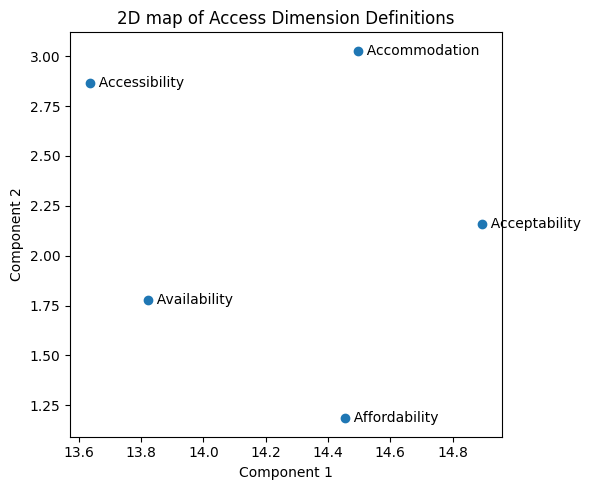

In [9]:
from umap import UMAP
reducer = UMAP(n_components=2, random_state=42, metric="cosine")
points_2d = reducer.fit_transform(def_embs)
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.scatter(points_2d[:,0], points_2d[:,1])

for (x, y), label in zip(points_2d, labels):
    plt.text(x, y, f"  {label}", va="center")

plt.title("2D map of Access Dimension Definitions")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.tight_layout()
plt.show()

### Create Topic Centroids

Apply topic model to dataset. Create centroids from reviews within topics. Freeze those centroids so they are available for later use so they do not have to be recalculated. 

In [10]:
def build_frozen_centroids(
    reviews: pd.DataFrame,
    text_col: str = "processedText",
    topic_model_dir: str = "bertopic_model",
    embedding_model_name: str = "all-MiniLM-L12-v2",
    out_npz: str = "topic_centroids_frozen.npz",
    out_csv: str | None = "topic_centroids_frozen.csv",
    batch_size: int = 1024,
    normalize: bool = True,
    drop_outlier_topic: bool = True,
):
    """
    1) Transforms all docs in reviews[text_col] with BERTopic to get topic IDs
    2) Embeds the same docs with SentenceTransformers
    3) Averages embeddings per topic to create stable centroids
    4) Saves centroids + metadata to disk (NPZ, optionally CSV)

    Returns: dict with keys: topic_ids, centroids, counts, meta
    """
    assert text_col in reviews.columns, f"{text_col} not in reviews"
    # Keep only non-empty strings
    docs = reviews[text_col].astype(str).str.strip()
    mask_usable = docs.ne("")
    docs = docs[mask_usable].tolist()
    if len(docs) == 0:
        raise ValueError("No usable documents in reviews[text_col].")

    # Load models
    embedding_model = SentenceTransformer(embedding_model_name)
    topic_model = BERTopic.load(topic_model_dir, embedding_model=embedding_model)

    # 1) Topic assignment
    topics, probs = topic_model.transform(docs)

    # 2) Embeddings (use the SAME docs, same order)
    #    encode in batches to avoid OOM on large corpora
    embs = embedding_model.encode(
        docs,
        batch_size=batch_size,
        convert_to_numpy=True,
        show_progress_bar=True,
        normalize_embeddings=normalize,   # normalize so cosine = dot
    )

    # 3) Collect vectors by topic
    topic_to_vecs = defaultdict(list)
    for t, v in zip(topics, embs):
        if drop_outlier_topic and t == -1:
            continue
        topic_to_vecs[t].append(v)

    if not topic_to_vecs:
        raise ValueError("No topics available to build centroids (all -1 or empty).")

    # 4) Mean vectors per topic (and L2 re-normalize if requested)
    topic_ids = sorted(topic_to_vecs.keys())
    centroids = []
    counts = []
    for t in topic_ids:
        arr = np.vstack(topic_to_vecs[t])
        mean_vec = arr.mean(axis=0)
        if normalize:
            denom = np.linalg.norm(mean_vec) + 1e-12
            mean_vec = mean_vec / denom
        centroids.append(mean_vec)
        counts.append(arr.shape[0])

    centroids = np.vstack(centroids).astype(np.float32)
    counts = np.asarray(counts, dtype=np.int32)
    topic_ids = np.asarray(topic_ids, dtype=np.int32)

    # 5) Metadata
    meta = {
        "created_utc": int(time.time()),
        "n_docs_input": int(len(docs)),
        "n_topics": int(len(topic_ids)),
        "embedding_model": embedding_model_name,
        "topic_model_dir": topic_model_dir,
        "normalized": bool(normalize),
        "drop_outlier_topic": bool(drop_outlier_topic),
        "text_col": text_col,
    }

    # 6) Save NPZ (primary artifact)
    np.savez_compressed(
        out_npz,
        topic_ids=topic_ids,
        centroids=centroids,
        counts=counts,
        meta=json.dumps(meta),
    )

    # Optional CSV for quick inspection
    if out_csv:
        df = pd.DataFrame(centroids)
        df.insert(0, "Topic", topic_ids)
        df.insert(1, "n_docs", counts)
        df.to_csv(out_csv, index=False)

    return {
        "topic_ids": topic_ids,
        "centroids": centroids,
        "counts": counts,
        "meta": meta,
        "out_npz": out_npz,
        "out_csv": out_csv,
    }

In [11]:
result = build_frozen_centroids(
     reviews,
     text_col="processedText",
     topic_model_dir="bertopic_model",
     embedding_model_name="all-MiniLM-L12-v2",
     out_npz="topic_centroids_frozen.npz",
     out_csv="topic_centroids_frozen.csv",
 )
print(result["meta"])

Batches: 100%|██████████| 1117/1117 [01:53<00:00,  9.84it/s]
2026-05-07 12:39:58,796 - BERTopic - Predicting topic assignments through cosine similarity of topic and document embeddings.
Batches: 100%|██████████| 35/35 [01:31<00:00,  2.60s/it]

{'created_utc': 1778172090, 'n_docs_input': 35731, 'n_topics': 59, 'embedding_model': 'all-MiniLM-L12-v2', 'topic_model_dir': 'bertopic_model', 'normalized': True, 'drop_outlier_topic': True, 'text_col': 'processedText'}


### Matching Inference Cosine Similarity

Using the saved embedded definitions and centroids, we measure cosine similarity from each topic centroid to defintion, then map those back to reviews. 

In [6]:
# Load Models
embedding_model = SentenceTransformer("all-MiniLM-L12-v2")
topic_model = BERTopic.load(
    "bertopic_model",
    embedding_model=embedding_model
)

# Transform ONLY usable docs (non-empty processedText) to get topic assignments and probabilities

# Stable row id so we can merge assignments back without dropping rows
reviews["__row_id"] = reviews.index.astype(int)

usable_reviews = reviews.loc[
    mask_usable,
    ["__row_id", "processedText"]
].copy()

docs = usable_reviews["processedText"].tolist()

topics, probs = topic_model.transform(docs)

# Robust probability handling: probs may be None, 1D, or 2D
if probs is None:
    try:
        probs = topic_model.approximate_distribution(docs)
    except Exception:
        probs = None

if probs is None:
    prob_max = np.full(len(docs), np.nan)
else:
    probs = np.asarray(probs)
    prob_max = probs if probs.ndim == 1 else probs.max(axis=1)

# Merge topic assignments back to full reviews dataframe
assign = pd.DataFrame({
    "__row_id": usable_reviews["__row_id"].values,
    "topic": topics,
    "topic_prob_max": prob_max
})

reviews = reviews.merge(assign, on="__row_id", how="left")

print("=== Topic assignment summary ===")
print(f"Total rows: {len(reviews):,}")
print(f"Usable for inference: {int(mask_usable.sum()):,}")
print(f"Not usable for inference: {int((~mask_usable).sum()):,}")
print(f"Assigned topics incl. -1: {int(reviews['topic'].notna().sum()):,}")
print(f"Unique topics excluding -1: {reviews.loc[reviews['topic'] != -1, 'topic'].dropna().nunique():,}")
print(f"BERTopic outlier topics (-1): {int((reviews['topic'] == -1).sum()):,}")

Batches: 100%|██████████| 1117/1117 [01:50<00:00, 10.12it/s]
2026-05-07 12:58:50,038 - BERTopic - Predicting topic assignments through cosine similarity of topic and document embeddings.


=== Topic assignment summary ===
Total rows: 35,779
Usable for inference: 35,731
Not usable for inference: 48
Assigned topics incl. -1: 35,731
Unique topics excluding -1: 59
BERTopic outlier topics (-1): 1,387


In [7]:
#Load frozen topic centroids

data = np.load("topic_centroids_frozen.npz", allow_pickle=True)

topic_ids = data["topic_ids"].astype(int)
centroids = data["centroids"]
counts = data["counts"]
meta = json.loads(data["meta"].item())

centroid_df = pd.DataFrame(centroids)
centroid_df.insert(0, "Topic", topic_ids)
centroid_df.insert(1, "n_docs", counts)

print("=== Frozen centroid artifact ===")
print(meta)
print(f"Loaded {len(topic_ids):,} topic centroids")

=== Frozen centroid artifact ===
{'created_utc': 1778172090, 'n_docs_input': 35731, 'n_topics': 59, 'embedding_model': 'all-MiniLM-L12-v2', 'topic_model_dir': 'bertopic_model', 'normalized': True, 'drop_outlier_topic': True, 'text_col': 'processedText'}
Loaded 59 topic centroids


In [8]:
#Load definitions and compute cosine similarities

DIM_ORDER = [
    "Availability",
    "Accessibility",
    "Accommodation",
    "Affordability",
    "Acceptability"
]

def_embs = np.load("data/definition_embeddings.npy").astype(np.float64)

# Re-normalize defensively
def_embs /= np.linalg.norm(def_embs, axis=1, keepdims=True) + 1e-12

centroids = centroids.astype(np.float64)
centroids /= np.linalg.norm(centroids, axis=1, keepdims=True) + 1e-12

# Cosine similarity = dot product because both matrices are L2-normalized
sim = centroids @ def_embs.T

sim_df = pd.DataFrame(
    sim,
    index=topic_ids,
    columns=DIM_ORDER
).sort_index()

display(sim_df.head())

,Availability,Accessibility,Accommodation,Affordability,Acceptability
0,0.438471,0.206785,0.322325,0.476315,0.385757
1,0.659282,0.561562,0.579297,0.733690,0.574402
2,0.226524,0.230685,0.135172,0.170842,0.199415
3,0.223693,0.221117,0.272730,0.429747,0.242457
4,0.451236,0.480433,0.521362,0.519236,0.486205


In [9]:
#Softmax-to-probs with margin-based runner-ups

def sims_to_probs(sim_df: pd.DataFrame,
                  temperature: float = 0.25,
                  margin_threshold: float | None = None,
                  top_k: int = 3) -> pd.DataFrame:
    """
    Convert topic–dimension cosine similarities into probabilistic assignments
    and apply a margin-based rule for multi-label classification.

    This function operates at the topic level. For each topic, it takes cosine
    similarities to each food-access dimension and converts them into a
    probability distribution using a temperature-scaled softmax:

        P(j | k) = exp(s_{jk} / τ) / Σ_j' exp(s_{j'k} / τ)

    where:
        - s_{jk} is the cosine similarity between topic k and dimension j
        - τ (temperature) controls how sharply probabilities concentrate on the top dimension

    After computing probabilities, the function assigns:
        - a primary label (the dimension with highest probability)
        - optional secondary and tertiary labels based on a margin rule

    Margin-based multi-label rule:
        Additional labels are included if their probability is sufficiently
        close to the top probability. Specifically, a dimension j is included if:

            P(top1 | k) - P(j | k) ≤ δ

        where δ = margin_threshold.

        - If margin_threshold is None, all top-k labels are returned (no filtering).
        - If margin_threshold is set (e.g., δ = 0.17), only dimensions within δ
          of the top probability are included as additional labels.
        - The rule is applied independently for top-2 and top-3 labels.

    Parameters
    ----------
    sim_df : pd.DataFrame
        DataFrame of cosine similarities with topics as rows and dimensions as columns.

    temperature : float, default=0.25
        Softmax temperature parameter. Lower values produce sharper (more peaked)
        probability distributions.

    margin_threshold : float or None, default=None
        Probability margin threshold δ for including additional labels.
        Smaller values make multi-label assignments more restrictive.

    top_k : int, default=3
        Maximum number of labels to consider (1, 2, or 3).

    Returns
    -------
    pd.DataFrame
        DataFrame containing:
        - original cosine similarities
        - softmax probabilities for each dimension
        - primary label (pred_dim, pred_prob)
        - optional secondary and tertiary labels (pred_dim2, pred_dim3)
        - probability margins used for thresholding
    """
    # --- Extract similarity matrix ---
    X = sim_df[DIM_ORDER].to_numpy(dtype=np.float64)
    
    # --- Center similarities (important for stability) ---
    Xc = X - X.mean(axis=1, keepdims=True)
    
    # --- Temperature-scaled softmax ---
    t = max(float(temperature), 1e-12)
    logits = Xc / t
    logits -= logits.max(axis=1, keepdims=True)  # numerical stability
    
    exps = np.exp(logits)
    probs = exps / exps.sum(axis=1, keepdims=True)

    # --- Store probabilities ---
    probs_df = pd.DataFrame(
        probs,
        columns=[f"{d}_p" for d in DIM_ORDER],
        index=sim_df.index
    )

    out = pd.concat([sim_df, probs_df], axis=1)

    # --- Rank dimensions by probability ---
    order = np.argsort(-probs, axis=1)
    top_probs = np.take_along_axis(probs, order, axis=1)

    # --- Top 1 (always assigned) ---
    top1_idx = order[:, 0]
    top1_prob = top_probs[:, 0]

    out["pred_dim"] = [DIM_ORDER[i] for i in top1_idx]
    out["pred_prob"] = top1_prob

    # --- Top 2 ---
    if top_k >= 2:
        top2_idx = order[:, 1]
        top2_prob = top_probs[:, 1]

        out["prob_margin"] = top1_prob - top2_prob

        if margin_threshold is not None:
            mask2 = out["prob_margin"] <= float(margin_threshold)
        else:
            mask2 = np.ones_like(top2_prob, dtype=bool)

        pred_dim2 = np.full(len(out), None, dtype=object)
        pred_prob2 = np.full(len(out), np.nan)

        pred_dim2[mask2] = [DIM_ORDER[i] for i in top2_idx[mask2]]
        pred_prob2[mask2] = top2_prob[mask2]

        out["pred_dim2"] = pred_dim2
        out["pred_prob2"] = pred_prob2

    # --- Top 3 ---
    if top_k >= 3:
        top3_idx = order[:, 2]
        top3_prob = top_probs[:, 2]

        prob_margin3 = top1_prob - top3_prob

        if margin_threshold is not None:
            mask3 = prob_margin3 <= float(margin_threshold)
        else:
            mask3 = np.ones_like(top3_prob, dtype=bool)

        pred_dim3 = np.full(len(out), None, dtype=object)
        pred_prob3 = np.full(len(out), np.nan)

        pred_dim3[mask3] = [DIM_ORDER[i] for i in top3_idx[mask3]]
        pred_prob3[mask3] = top3_prob[mask3]

        out["pred_dim3"] = pred_dim3
        out["pred_prob3"] = pred_prob3

    return out


In [10]:
#create softmax probabilities and apply margin-based multi-label rule
soft_df = sims_to_probs(
    sim_df,
    temperature=0.11,
    margin_threshold=0.17,
    top_k=3
)

soft_df["Topic"] = soft_df.index

print("=== Soft assignment summary ===")
print(f"Total topics: {len(soft_df):,}")
print(f"Single-label topics: {(soft_df['pred_dim2'].isna()).sum():,}")
print(f"Multi-label (2+) topics: {(soft_df['pred_dim2'].notna()).sum():,}")
print(f"Triple-label topics: {(soft_df['pred_dim3'].notna()).sum():,}")


=== Soft assignment summary ===
Total topics: 59
Single-label topics: 28
Multi-label (2+) topics: 31
Triple-label topics: 25


Merge Topic Info with soft df (so that we have full topic representations)

In [11]:
soft_df["Topic"] = soft_df.index


# ========= Add BERTopic topic metadata to soft_df =========

# Get topic-level metadata from BERTopic
topic_info = topic_model.get_topic_info().copy()
topic_info["Topic"] = topic_info["Topic"].astype(int)

# Keep only the topic metadata columns we want, if they exist
desired_topic_info_cols = [
    "Topic",
    "Name",
    "Representation",
    "OpenAI",
]

topic_info_cols = [
    col for col in desired_topic_info_cols
    if col in topic_info.columns
]

topic_info_keep = topic_info[topic_info_cols].copy()

# Merge topic metadata onto soft assignment table
soft_df = soft_df.merge(
    topic_info_keep,
    on="Topic",
    how="left",
    validate="one_to_one"
)

In [12]:
soft_df.head()

,Availability,Accessibility,Accommodation,Affordability,Acceptability,Availability_p,Accessibility_p,Accommodation_p,Affordability_p,Acceptability_p,...,pred_prob,prob_margin,pred_dim2,pred_prob2,pred_dim3,pred_prob3,Topic,Name,Representation,OpenAI
0,0.438471,0.206785,0.322325,0.476315,0.385757,0.285758,0.034775,0.099411,0.403097,0.176959,...,0.403097,0.117339,Availability,0.285758,None,NaN,0,0_meat_meats_meat department_butcher,"[meat, meats, meat department, butcher, depart...",[Meat Department Quality]
1,0.659282,0.561562,0.579297,0.733690,0.574402,0.231282,0.095133,0.111776,0.454898,0.106911,...,0.454898,0.223617,None,NaN,None,NaN,1,1_groceries_grocery_grocery store_place,"[groceries, grocery, grocery store, place, gro...",[Grocery Shopping Preferences]
2,0.226524,0.230685,0.135172,0.170842,0.199415,0.259152,0.269142,0.112949,0.156211,0.202546,...,0.269142,0.009990,Availability,0.259152,Acceptability,0.202546,2,2_experience_place_visit_good experience,"[experience, place, visit, good experience, lo...",[Positive Visit Experiences]
3,0.223693,0.221117,0.272730,0.429747,0.242457,0.089018,0.086957,0.139021,0.579430,0.105574,...,0.579430,0.440409,None,NaN,None,NaN,3,3_prices_high_quality_low,"[prices, high, quality, low, prices good, chea...",[Price Perception]
4,0.451236,0.480433,0.521362,0.519236,0.486205,0.134670,0.175608,0.254765,0.249886,0.185070,...,0.254765,0.004879,Affordability,0.249886,Acceptability,0.185070,4,4_store_prices_great store_nice store,"[store, prices, great store, nice store, shop,...",[Consumer behavior in retail]


Merge back to reviews dataframe. 

In [13]:
# Ensure Topic column exists in soft_df
soft_df = soft_df.copy()
soft_df["Topic"] = soft_df["Topic"].astype(int)

# Merge topic-level predictions, probabilities, and topic metadata onto review-level data
reviews = reviews.merge(
    soft_df[
        [
            "Topic",
            "pred_dim", "pred_prob",
            "pred_dim2", "pred_prob2",
            "pred_dim3", "pred_prob3",
            "prob_margin",
            "Availability_p",
            "Accessibility_p",
            "Accommodation_p",
            "Affordability_p",
            "Acceptability_p",
            "Name",
            "Representation",
            "OpenAI",
        ]
    ],
    left_on="topic",
    right_on="Topic",
    how="left",
    validate="many_to_one"
)

# Drop duplicate Topic column
reviews = reviews.drop(columns=["Topic"])

In [14]:
print("=== Post-merge summary ===")
print(f"Total reviews: {len(reviews):,}")
print(f"Reviews with topic assigned: {reviews['topic'].notna().sum():,}")
print(f"Reviews with dimension assigned: {reviews['pred_dim'].notna().sum():,}")
print(f"Reviews with multi-label (2+): {reviews['pred_dim2'].notna().sum():,}")

=== Post-merge summary ===
Total reviews: 35,779
Reviews with topic assigned: 35,731
Reviews with dimension assigned: 34,344
Reviews with multi-label (2+): 16,234


Save reviews df with dimensions added. 

In [15]:
output_path = "data/reviews_with_dimensions.csv"
#reviews.to_csv(output_path, index=False)

#print(f"Saved to: {output_path}")

Saved to: data/reviews_with_dimensions.csv


In [19]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35779 entries, 0 to 35778
Data columns (total 63 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   address                  35779 non-null  object 
 1   categoryName             35779 non-null  object 
 2   cid                      35779 non-null  uint64 
 3   city                     35779 non-null  object 
 4   countryCode              35779 non-null  object 
 5   error                    0 non-null      float64
 6   fid                      35779 non-null  object 
 7   isAdvertisement          35779 non-null  bool   
 8   isLocalGuide             35779 non-null  bool   
 9   language                 35779 non-null  object 
 10  likesCount               35779 non-null  float64
 11  location/lat             35779 non-null  float64
 12  location/lng             35779 non-null  float64
 13  name                     35779 non-null  object 
 14  originalLanguage      